## 1. HST Calibration

#### importing libraries 

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

## Part 1: defining functions

### a. Loading files

In [102]:
# defining a function to unpack and name all files 
def load_files(name, path):
    image = fits.open(f'{path}/{name}/{name}_raw.fits')
    maskfile = fits.open(f'{path}/{name}/{name}_maskfile.fits')
    blevfile = fits.open(f'{path}/{name}/{name}_blevfile.fits')
    biasfile = fits.open(f'{path}/{name}/{name}_biasfile.fits')
    darkfile = fits.open(f'{path}/{name}/{name}_darkfile.fits')
    flatfile = fits.open(f'{path}/{name}/{name}_flatfile.fits')
    return image, maskfile, blevfile, biasfile, darkfile, flatfile

In [103]:
# some images had data in differnt extensions
def get_pixels(image):
    for hdu in image:
        if hdu.data is not None and hdu.data.ndim == 3:
            return hdu.data

### b. Masking invalid data

In [104]:
def mask(pixels, mask):
    # 2 = defective pixels - replace 2 values with NaN
    return np.where(mask==2, np.nan, pixels) 

### c. Bias level correction

In [105]:
def get_blev(blevfile, chip):
    if blevfile[0].data is not None:
        return blevfile[0].data[chip]
    return blevfile[chip+1].data

In [106]:
def blev_corr(pixels, blevfile):
    pixelsb = pixels.copy()
    #taking data from each blev file 
    for i in range(4):
        blev = get_blev(blevfile, i)
        print('shape =', np.shape(blev), "for chip", i)
        odd_vals = blev[9:790, 8:14:2]
        even_vals = blev[9:790, 9:14:2]
        odd_bias = np.mean(odd_vals)
        even_bias = np.mean(even_vals)
        print("Odd bias = ", odd_bias, "for chip", i)
        print("Even bias =", even_bias, 'for chip', i)
        pixelsb[i, :, 0::2] = pixels[i, :, 0::2] - odd_bias  
        pixelsb[i, :, 1::2] = pixels[i, :, 1::2] - even_bias
    return pixelsb

### d. bias, dark and flat correction

In [107]:
#bias, dark and flat corrections
def calibration(pixels, bias, dark, flat, exptime, flat_threshold = 1.3):
    #checking shape of each file 
    print('bias shape:',np.shape(bias),"dark shape:", np.shape(dark),"flat shape:", np.shape(flat))
    #checking flat values 
    print('flat min, mean, max =', np.nanmin(flat), np.nanmean(flat), np.nanmax(flat))
    #calibrating image
    pixelsc = pixels - bias
    pixelsc = pixelsc - (exptime*dark)
    pixelsc = pixelsc * flat
    # flat values abnormally large at edges 
    pixelsc[flat > flat_threshold] = np.nan
    return pixelsc

### e. sky correction

In [108]:
# sky correction - subtracting median counts of image 
def sky_corr(pixels):
    pixelsd = pixels.copy()
    for i in range(4):
        sky = np.nanmedian(pixels[i])
        print("sky =", sky, 'for chip', i)
        pixelsd[i] = pixels[i] - sky
    return pixelsd

### f. photometry

In [109]:
# extracting data from science ready files 
def photomety(sciencefile):
    # photometry calibration values from the science ready images
    science = fits.open(sciencefile)
    science_header = science['SCI'].header
    photflam = science_header['PHOTFLAM']
    photzpt = science_header['PHOTZPT']
    zp_corr = science_header['ZP_CORR']
    print(photflam, photzpt, zp_corr)
    return photflam, photzpt, zp_corr

In [110]:
# calculating flux 

def flux_calc(pixels, exptime, photflam):
    count_rate = pixels/exptime
    flux = count_rate*photflam
    return flux 

In [111]:
# calculating magnitude 
def magnitude(flux, photzpt):
    #apparant magnitude from flux 
    mag = np.full(flux.shape, np.nan)
    positive = np.isfinite(flux) & (flux >0)
    mag[positive] = -2.5*np.log10(flux[positive]) + photzpt
    return mag 

### g. plots of images 

In [112]:
def plot(pixels, name): 
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    for i, ax in enumerate(axes.flatten()):
        img = pixels[i]
        vmin, vmax = np.nanpercentile(img, [1, 99.5])
        im = ax.imshow(img, origin='lower', vmin=vmin, vmax=vmax)
        plt.colorbar(im, ax=ax, label='DN')
        ax.set_title(f"Calibrated Image {name} chip {i}")
        ax.set_xlabel("x pixel")
        ax.set_ylabel("y pixel")
    plt.tight_layout()
    plt.show()

### h. calling all functions at once

In [113]:
def run_all(name, sciencefile, path):
    #defining needed data
    image, maskfile, blevfile, biasfile, darkfile, flatfile = load_files(name, path)
    pixels = get_pixels(image) 
    print("image shape of ", name, ":", np.shape(pixels))
    exptime = image[0].header["EXPTIME"]
    print('exptime of', name, ":", exptime)
    #calling each function 
    pixelsa = mask(pixels, maskfile[0].data)
    pixelsb = blev_corr(pixelsa, blevfile)
    pixelsc = calibration(pixelsb, biasfile[0].data, darkfile[0].data, flatfile[0].data, exptime)
    pixelsd = sky_corr(pixelsc)
    #extracting data from science ready files 
    photflam, photzpt, zp_corr = photomety(sciencefile)
    flux = flux_calc(pixelsd, exptime, photflam)
    mag = magnitude(flux, photzpt)
    return pixelsd, flux, mag, exptime, photflam, photzpt, zp_corr

## Part 2. applying to files 

### a. extracting science ready data from images

In [114]:
results = {}
for name in ['ubai2505m', 'ubai2507m', 'ubai2508m']:
    results[name] = run_all(name, f'hst-data/F336W/{name}_c0m_aligned.fits', 'hst-data/calibration')

image shape of  ubai2505m : (4, 800, 800)
exptime of ubai2505m : 700.0
shape = (800, 14) for chip 0
Odd bias =  299.58472044387537 for chip 0
Even bias = 299.59154929577466 for chip 0
shape = (800, 14) for chip 1
Odd bias =  319.96030729833547 for chip 1
Even bias = 319.93341869398205 for chip 1
shape = (800, 14) for chip 2
Odd bias =  313.48314127187365 for chip 2
Even bias = 313.46478873239437 for chip 2
shape = (800, 14) for chip 3
Odd bias =  298.7443448570209 for chip 3
Even bias = 298.74989329918907 for chip 3
bias shape: (4, 800, 800) dark shape: (4, 800, 800) flat shape: (4, 800, 800)
flat min, mean, max = 0.009630168 5.6277857 150.95598
sky = 0.7816752673268986 for chip 0
sky = 0.5081851399924808 for chip 1
sky = 0.0546498393737977 for chip 2
sky = 0.7110299781771136 for chip 3
1.115396e-16 -21.1 -0.03288031
image shape of  ubai2507m : (4, 800, 800)
exptime of ubai2507m : 700.0
shape = (800, 14) for chip 0
Odd bias =  299.5591122492531 for chip 0
Even bias = 299.55783183952195

### b. plotting all data 

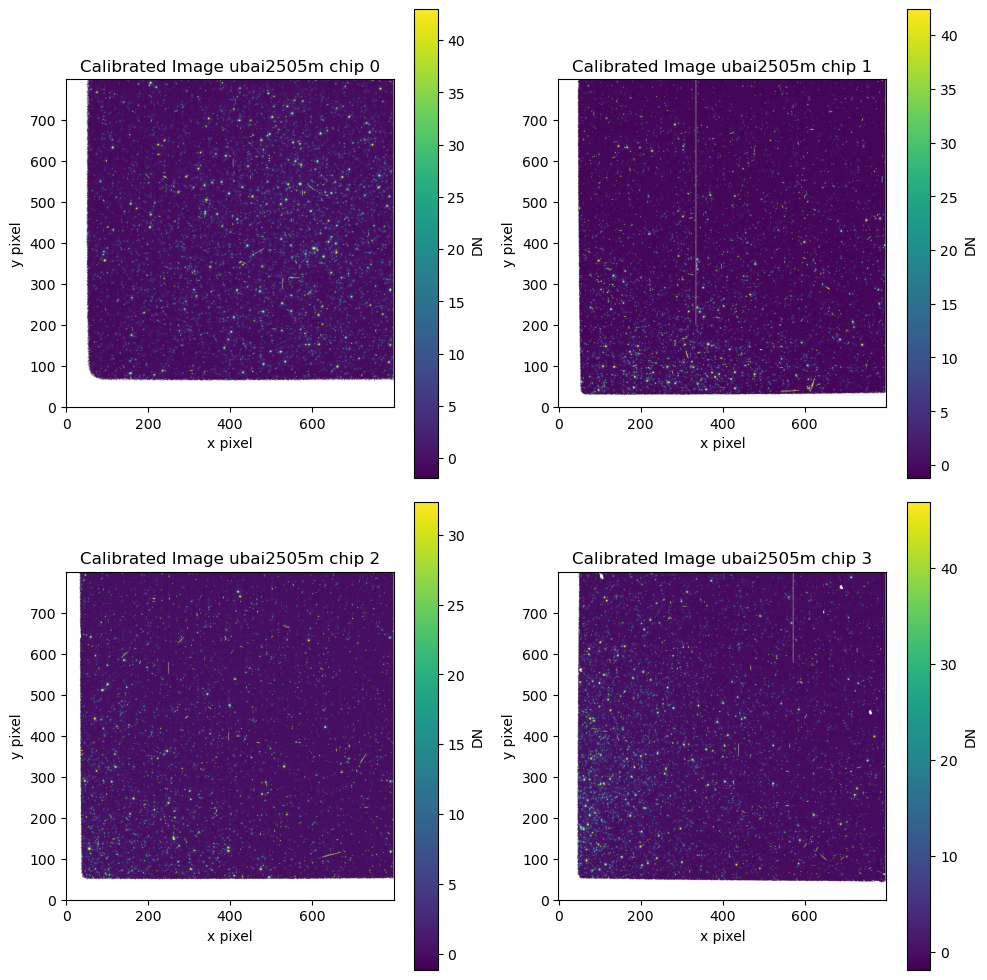

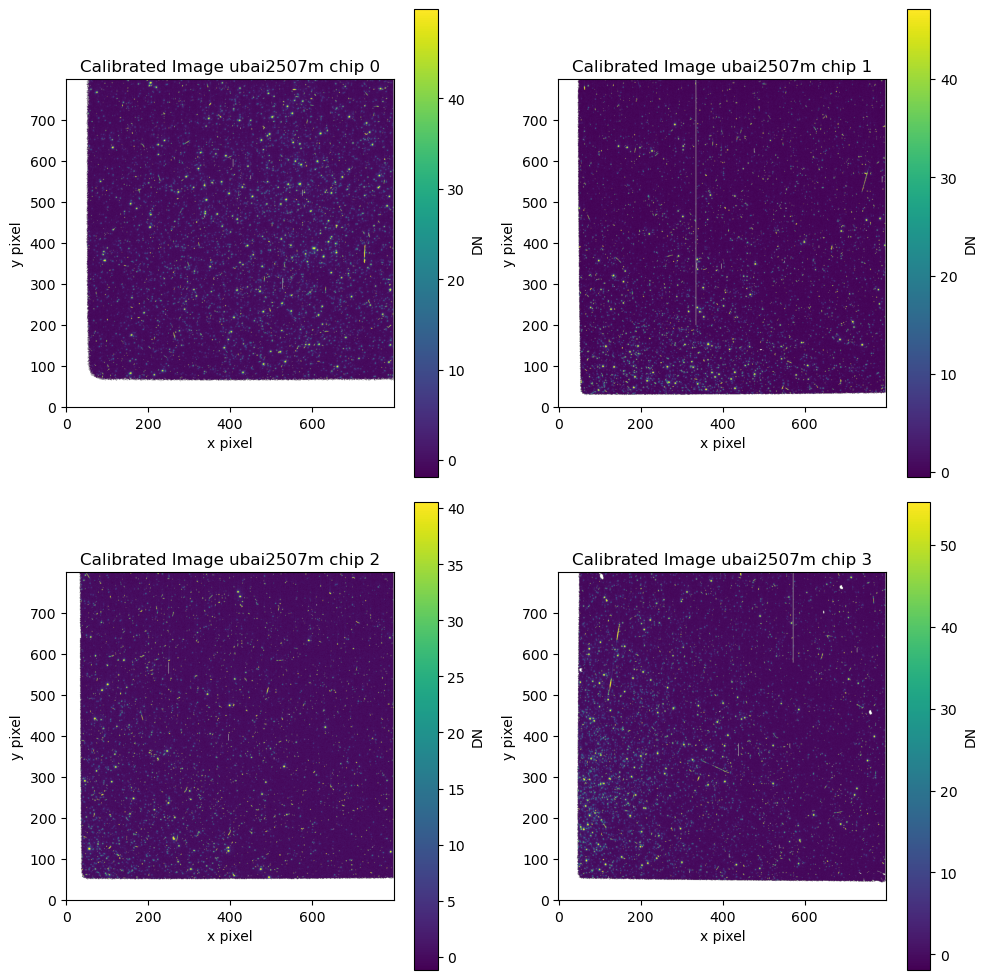

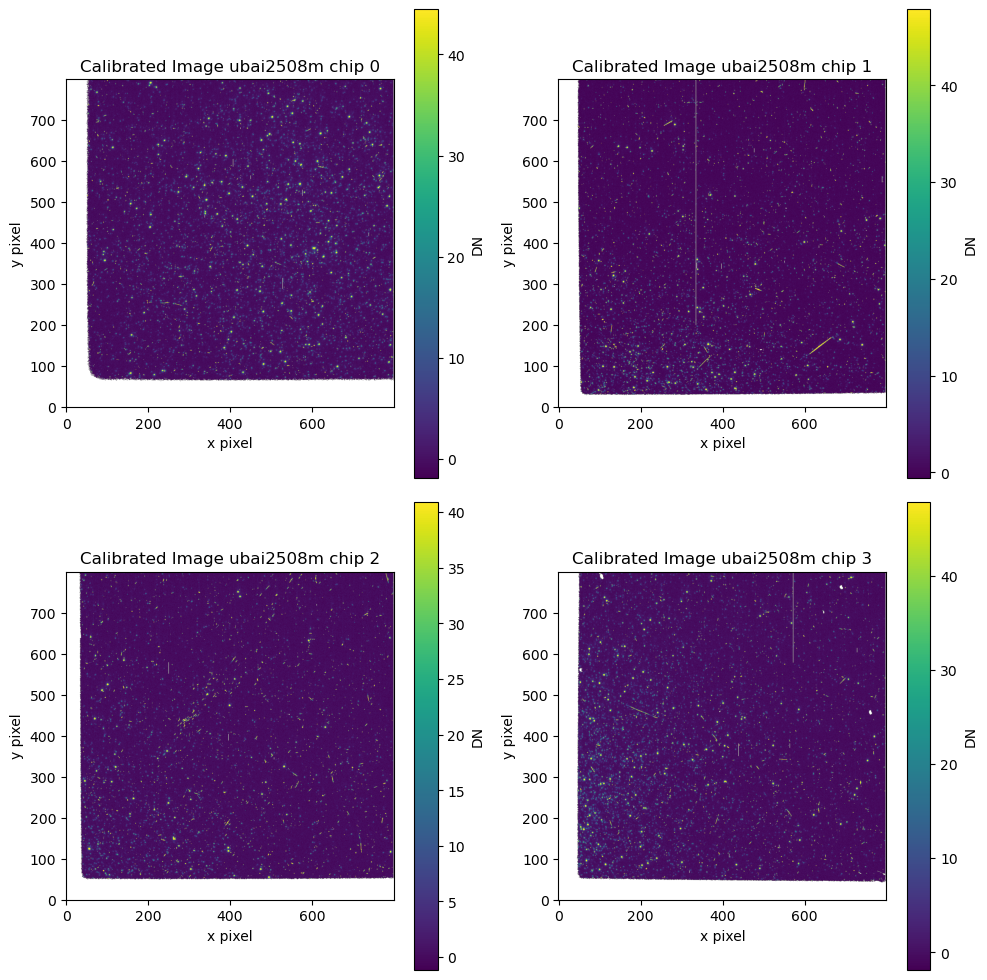

In [115]:
for name in results:
    plot(results[name][0], name)

## Part 3. Saving calibrated data 

In [126]:
def save(name, result, outpath ='hst-processed'):
    pixelsd, flux, mag, exptime, photflam, photzpt, zp_corr = result
    #creating hst-processed folder
    os.makedirs(outpath, exist_ok = True)
    #making headers - data used in calibration
    primary = fits.PrimaryHDU()
    primary.header['ROOTNAME'] = name
    primary.header['EXPTIME'] = exptime
    primary.header['PHOTFLAM'] = photflam
    primary.header['PHOTZPT'] = photzpt
    primary.header['ZP_CORR'] = zp_corr
    #extensions for the pixels, flux and magnitudes
    pixels_hdu = fits.ImageHDU(pixelsd.astype('float32'), name = "Pixels")
    pixels_hdu.header["BUNIT"] = "DN"
    flux_hdu = fits.ImageHDU(flux.astype('float32'), name='Flux')
    flux_hdu.header["BUNIT"] = 'erg/s/cm^2/A'
    magnitude_hdu = fits.ImageHDU(mag.astype("float32"), name ="Mag")
    magnitude_hdu.header["BUNIT"] = "STMAG"
    
    hdul = fits.HDUList([primary, pixels_hdu,flux_hdu, magnitude_hdu])
    hdul.writeto(f'{outpath}/{name}_calibrated.fits', overwrite=True)
    print("saved", (os.path.abspath(f'{outpath}/{name}_calibrated.fits')))

In [127]:
for name in results:
    save(name, results[name])

saved /Users/hannaholearyjeffers/Documents/Space Lab 2026 /Assignment 2/repo-fix/exercise-1-calibration/hst-processed/ubai2505m_calibrated.fits
saved /Users/hannaholearyjeffers/Documents/Space Lab 2026 /Assignment 2/repo-fix/exercise-1-calibration/hst-processed/ubai2507m_calibrated.fits
saved /Users/hannaholearyjeffers/Documents/Space Lab 2026 /Assignment 2/repo-fix/exercise-1-calibration/hst-processed/ubai2508m_calibrated.fits
